# CAI20303 Machine Learning - Assignment 2
## Crop Recommendation System using Ensemble Learning and Support Vector Machine

**Dataset:** `Group8_Crop_Recommendation_1760.csv`  
**Samples:** 1,760 (within the assignment requirement of 1,000-2,000)  
**Task:** Multiclass classification  
**Input features:** N, P, K, temperature, humidity, pH, rainfall  
**Target:** `label` (22 crop classes)  
**Random seed:** 42

### Problem context
Farmers must select crops that suit local soil nutrients and environmental conditions. A poor crop choice can reduce yield and waste water, fertiliser, labour, and land resources. This project formulates crop recommendation as a **multiclass classification problem**: seven numeric measurements are used to predict one of 22 crop classes.

The notebook follows the Assignment 2 structure: environment and reproducibility, data loading and description, exploratory data analysis, preprocessing, an ensemble model, an SVM, hyperparameter tuning, evaluation, model comparison, best-model selection, and three prediction examples.

## 1. Environment & Reproducibility

In [3]:
import sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1


## 2. Data Loading & Description
Upload `Group8_Crop_Recommendation_1760.csv` when prompted. If it is already in the Colab working directory, it loads automatically.

In [4]:
import os
FILE_NAME = 'Group8_Crop_Recommendation_1760.csv'
if not os.path.exists(FILE_NAME):
    from google.colab import files
    print(f'Please upload {FILE_NAME}')
    uploaded = files.upload()
    if FILE_NAME not in uploaded:
        FILE_NAME = next(iter(uploaded))
df = pd.read_csv(FILE_NAME)
print('Loaded:', FILE_NAME)
print('Shape:', df.shape)
display(df.head())

Please upload Group8_Crop_Recommendation_1760.csv


Saving Group8_Crop_Recommendation_1760.csv to Group8_Crop_Recommendation_1760.csv
Loaded: Group8_Crop_Recommendation_1760.csv
Shape: (1760, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,29,121,196,22.848528,94.321302,6.079497,123.597784,apple
1,38,135,203,23.761218,93.661643,5.965551,100.825956,apple
2,13,144,197,22.921571,94.896134,6.280223,105.694154,apple
3,25,143,200,23.804363,92.804416,6.024249,100.619254,apple
4,13,126,204,23.109427,92.796308,6.383180,108.183792,apple


In [5]:
FEATURES = ['N','P','K','temperature','humidity','ph','rainfall']
TARGET = 'label'
expected = FEATURES + [TARGET]
assert list(df.columns) == expected, f'Expected columns {expected}, found {list(df.columns)}'
assert len(df) == 1760, f'Expected 1,760 rows, found {len(df)}'
print('Data types:')
display(df.dtypes.to_frame('dtype'))
df.info()
print('\nCrop classes:', df[TARGET].nunique())
print(sorted(df[TARGET].unique()))

Data types:


,dtype
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1760 entries, 0 to 1759
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            1760 non-null   int64  
 1   P            1760 non-null   int64  
 2   K            1760 non-null   int64  
 3   temperature  1760 non-null   float64
 4   humidity     1760 non-null   float64
 5   ph           1760 non-null   float64
 6   rainfall     1760 non-null   float64
 7   label        1760 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 110.1+ KB

Crop classes: 22
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


### Variables
| Variable | Role | Description |
|---|---|---|
| N | Input | Nitrogen content in soil |
| P | Input | Phosphorus content in soil |
| K | Input | Potassium content in soil |
| temperature | Input | Environmental temperature in degrees Celsius |
| humidity | Input | Relative humidity percentage |
| ph | Input | Soil acidity or alkalinity |
| rainfall | Input | Rainfall in millimetres |
| label | Target | Recommended crop among 22 classes |

Add the exact public dataset creator, source URL, access date, and collection method to the written report.

## 3. Exploratory Data Analysis (EDA)

In [6]:
quality = pd.DataFrame({'missing_values': df.isna().sum(),
                        'missing_percent': (df.isna().mean()*100).round(2),
                        'unique_values': df.nunique()})
display(quality)
print('Duplicate rows:', df.duplicated().sum())
display(df[FEATURES].describe().T)

,missing_values,missing_percent,unique_values
N,0,0.0,135
P,0,0.0,117
K,0,0.0,73
temperature,0,0.0,1760
humidity,0,0.0,1760
ph,0,0.0,1760
rainfall,0,0.0,1760
label,0,0.0,22


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
N,1760.0,50.547727,36.862820,0.000000,21.000000,37.000000,85.000000,140.000000
P,1760.0,53.339773,32.947620,5.000000,28.000000,51.000000,68.000000,145.000000
K,1760.0,48.143182,50.708802,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,1760.0,25.609409,5.080371,8.825675,22.782207,25.518655,28.550513,43.675493
humidity,1760.0,71.416762,22.280828,14.258040,60.195432,80.542322,89.908373,99.981876
ph,1760.0,6.473830,0.783290,3.504752,5.955924,6.431478,6.931730,9.935091
rainfall,1760.0,103.451590,54.992615,20.211267,64.551686,94.772563,123.592008,298.560117


**Cleaning strategy:** Rows with a missing target are removed. Numeric missing values, if any, are replaced using the training-set median through a pipeline-safe approach. Exact duplicates are removed only when present. Potential outliers are inspected but not automatically deleted because extreme agricultural conditions may distinguish crops.

In [7]:
clean_df = df.dropna(subset=[TARGET]).drop_duplicates().reset_index(drop=True)
for col in FEATURES:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())
print('Original rows:', len(df))
print('Rows after justified cleaning:', len(clean_df))
print('Remaining missing values:', clean_df.isna().sum().sum())

Original rows: 1760
Rows after justified cleaning: 1760
Remaining missing values: 0


In [8]:
outliers=[]
for col in FEATURES:
    q1,q3=clean_df[col].quantile([.25,.75]); iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr
    outliers.append([col,lo,hi,((clean_df[col]<lo)|(clean_df[col]>hi)).sum()])
display(pd.DataFrame(outliers,columns=['Feature','Lower IQR bound','Upper IQR bound','Potential outliers']))

,Feature,Lower IQR bound,Upper IQR bound,Potential outliers
0,N,-75.000000,181.000000,0
1,P,-32.000000,128.000000,108
2,K,-23.500000,92.500000,160
3,temperature,14.129748,37.202971,72
4,humidity,15.626020,134.477785,24
5,ph,4.492216,8.395438,43
6,rainfall,-24.008797,212.152490,82


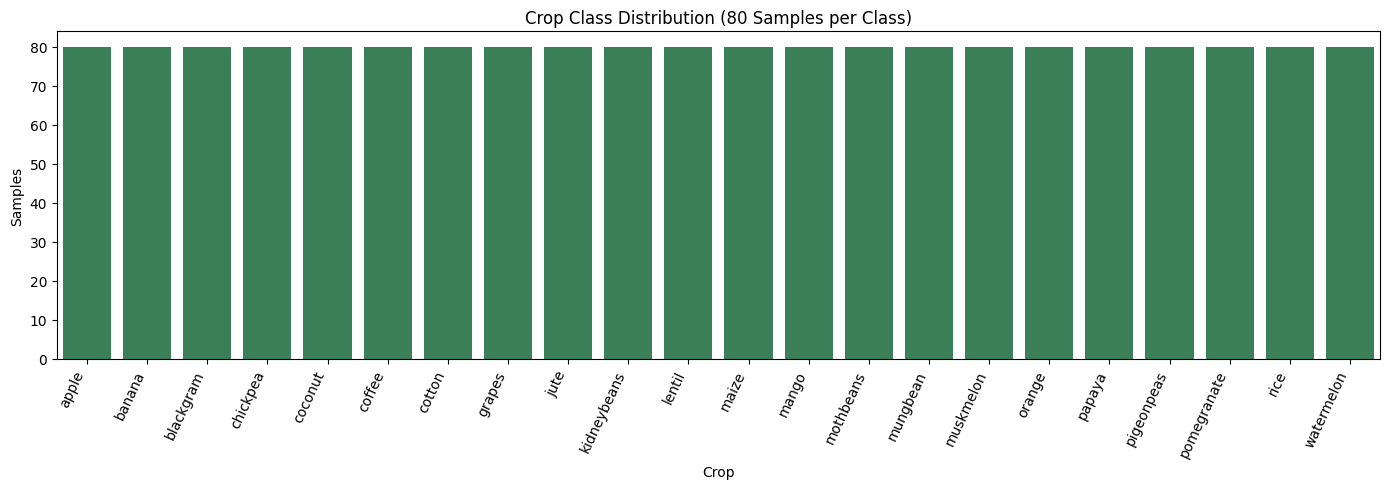

label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
count,80,80,80,80,80,80,80,80,80,80,...,80,80,80,80,80,80,80,80,80,80


In [9]:
counts=clean_df[TARGET].value_counts().sort_index()
plt.figure(figsize=(14,5))
sns.barplot(x=counts.index,y=counts.values,color='seagreen')
plt.title('Crop Class Distribution (80 Samples per Class)')
plt.xlabel('Crop'); plt.ylabel('Samples'); plt.xticks(rotation=65,ha='right'); plt.tight_layout(); plt.show()
display(counts.to_frame('count').T)

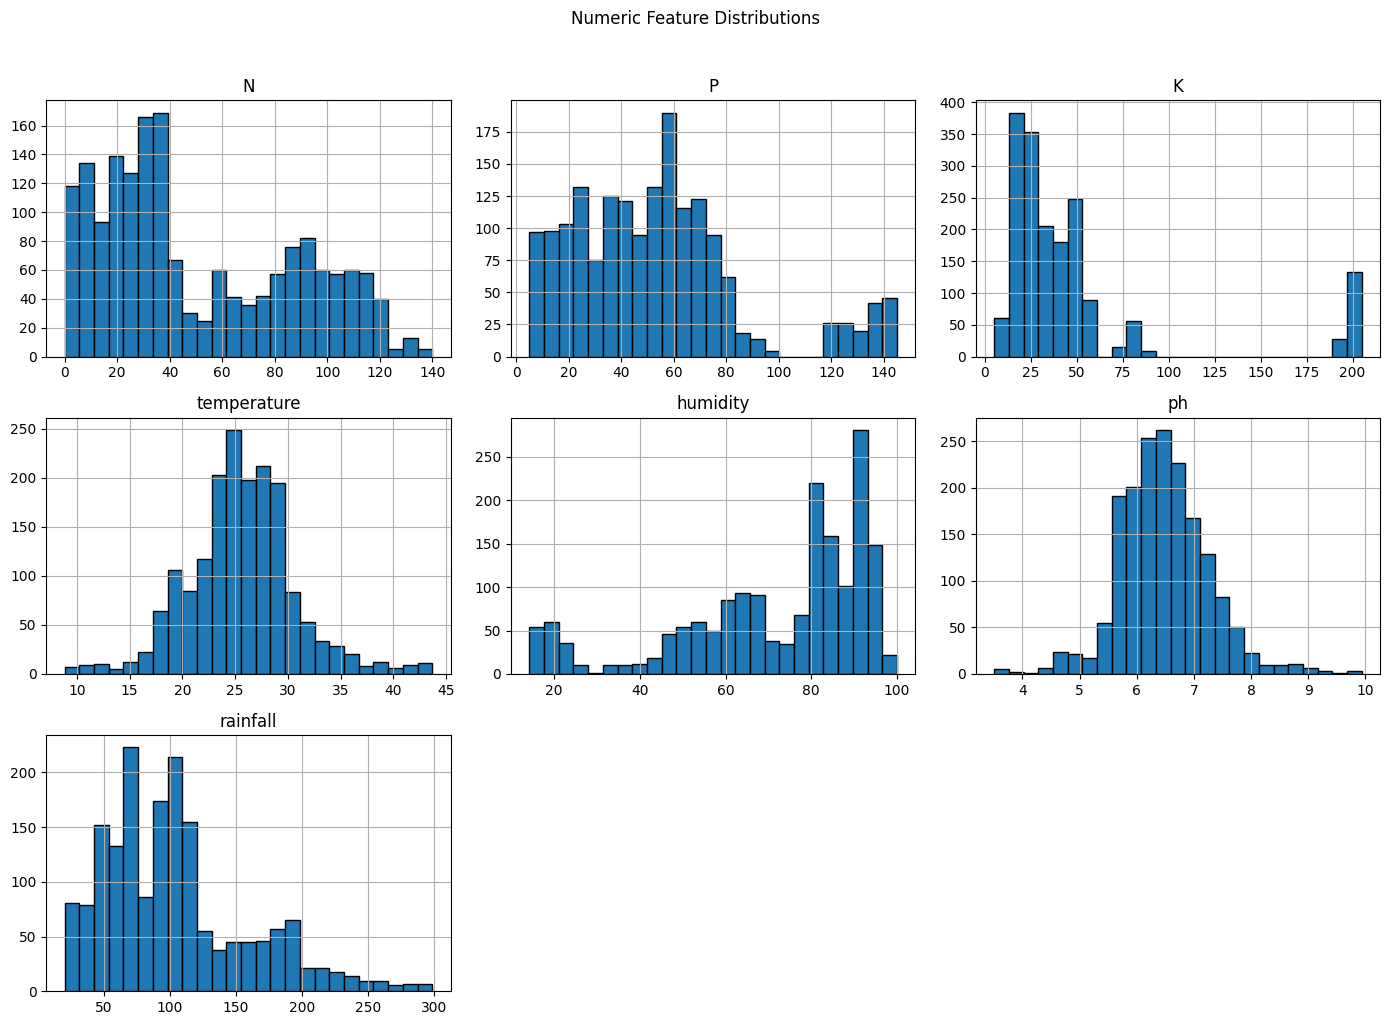

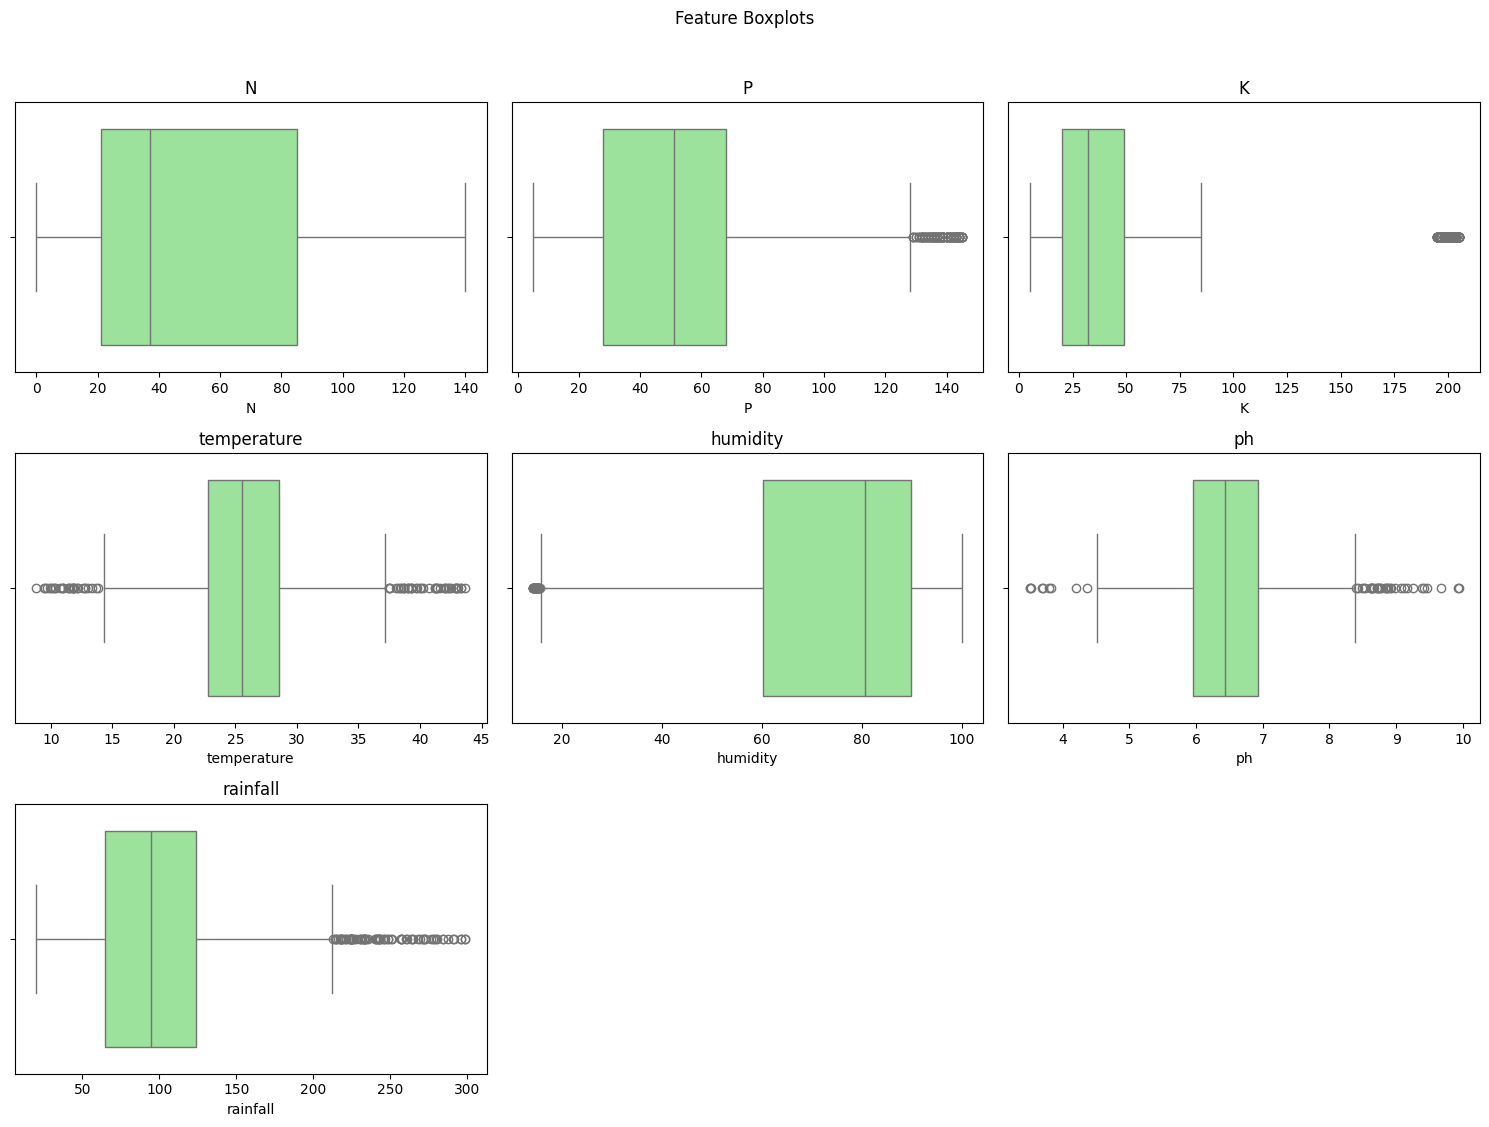

In [10]:
clean_df[FEATURES].hist(figsize=(14,10),bins=25,edgecolor='black')
plt.suptitle('Numeric Feature Distributions',y=1.02); plt.tight_layout(); plt.show()
fig,axes=plt.subplots(3,3,figsize=(15,11))
for ax,col in zip(axes.flat,FEATURES):
    sns.boxplot(x=clean_df[col],ax=ax,color='lightgreen'); ax.set_title(col)
for ax in axes.flat[len(FEATURES):]: ax.axis('off')
plt.suptitle('Feature Boxplots',y=1.02); plt.tight_layout(); plt.show()

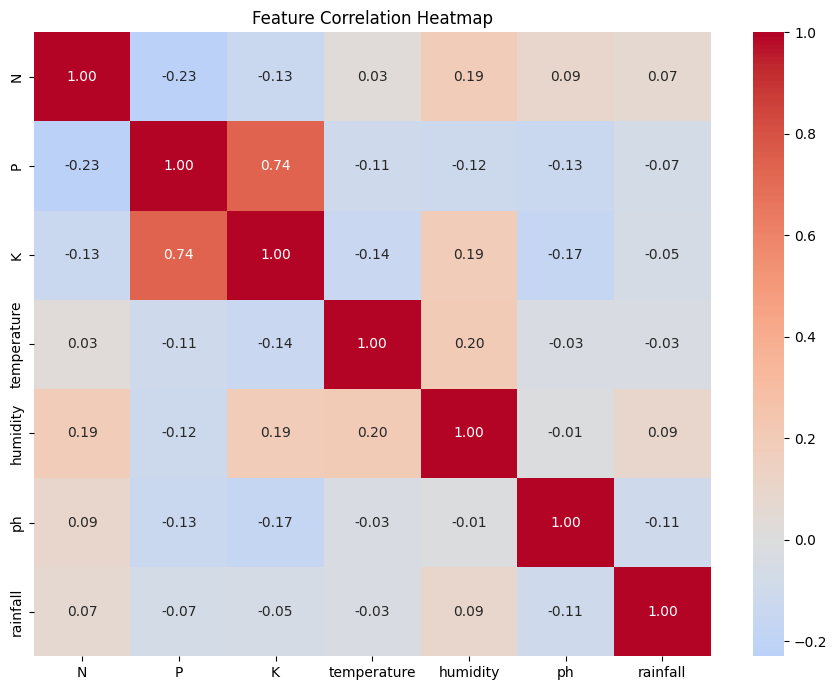

In [11]:
plt.figure(figsize=(9,7))
sns.heatmap(clean_df[FEATURES].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Feature Correlation Heatmap'); plt.tight_layout(); plt.show()

In [12]:
crop_means=clean_df.groupby(TARGET)[FEATURES].mean().round(2)
display(crop_means)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,21.42,134.38,200.09,22.66,92.29,5.94,112.35
banana,100.48,82.00,50.01,27.47,80.39,5.97,104.74
blackgram,39.56,67.66,19.23,29.79,64.97,7.13,67.74
chickpea,40.35,67.65,79.72,18.94,16.85,7.37,79.87
coconut,22.42,16.69,30.54,27.37,94.80,5.97,174.63
coffee,101.68,28.92,29.90,25.57,58.86,6.78,158.01
cotton,116.81,46.51,19.64,23.92,80.09,6.93,80.65
grapes,23.38,132.10,200.35,24.25,81.83,6.01,69.70
jute,78.06,47.12,39.89,24.87,79.13,6.74,175.81


## 4. Model Development

Two required model families are compared:

1. **Random Forest (Ensemble):** combines many decision trees and uses majority voting. It captures nonlinear interactions, is robust, and provides feature importance.
2. **Support Vector Machine (SVM):** finds separating boundaries with maximum margin. The RBF kernel can model nonlinear class boundaries. Standardisation is essential because SVM distance calculations are scale-sensitive.

A stratified 80/20 split preserves all crop proportions in training and testing. The test set is held out and is not used during tuning.

In [13]:
X=clean_df[FEATURES]; y=clean_df[TARGET]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
print('Training set:',X_train.shape)
print('Test set:',X_test.shape)
print('Samples per crop in training:',y_train.value_counts().unique())
print('Samples per crop in testing:',y_test.value_counts().unique())

Training set: (1408, 7)
Test set: (352, 7)
Samples per crop in training: [64]
Samples per crop in testing: [16]


In [14]:
rf_baseline=RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1)
rf_baseline.fit(X_train,y_train)
rf_pred=rf_baseline.predict(X_test)
svm_model=Pipeline([('scaler',StandardScaler()),('svm',SVC(kernel='rbf',C=1.0,gamma='scale'))])
svm_model.fit(X_train,y_train)
svm_pred=svm_model.predict(X_test)
print('Baseline models trained.')

Baseline models trained.


## 5. Hyperparameter Tuning

Random Forest is tuned using five-fold stratified cross-validation. The grid tunes more than the required two parameters:

- `n_estimators`: number of trees; more trees can stabilise predictions but increase computation.
- `max_depth`: maximum tree depth; controls model complexity and overfitting.
- `min_samples_split`: minimum samples required to split a node; larger values regularise trees.
- `max_features`: number of features considered at each split; controls tree diversity.

`f1_macro` is used for tuning so every crop class contributes equally to model selection.

In [15]:
param_grid={'n_estimators':[100,200],
            'max_depth':[None,15,25],
            'min_samples_split':[2,5],
            'max_features':['sqrt','log2']}
grid_search=GridSearchCV(RandomForestClassifier(random_state=SEED,n_jobs=-1),
                         param_grid,scoring='f1_macro',cv=5,n_jobs=-1,verbose=1,
                         return_train_score=True)
grid_search.fit(X_train,y_train)
rf_tuned=grid_search.best_estimator_
rf_tuned_pred=rf_tuned.predict(X_test)
print('Best parameters:',grid_search.best_params_)
print('Best CV macro F1:',round(grid_search.best_score_,4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Best CV macro F1: 0.9936


In [16]:
def metrics(name,true,pred):
    return {'Model':name,'Accuracy':accuracy_score(true,pred),
            'Macro Precision':precision_score(true,pred,average='macro',zero_division=0),
            'Macro Recall':recall_score(true,pred,average='macro',zero_division=0),
            'Macro F1':f1_score(true,pred,average='macro',zero_division=0)}
tuning_comparison=pd.DataFrame([metrics('Random Forest - Baseline',y_test,rf_pred),
                                metrics('Random Forest - Tuned',y_test,rf_tuned_pred)]).set_index('Model')
display(tuning_comparison.round(4))

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Random Forest - Baseline,1.0,1.0,1.0,1.0
Random Forest - Tuned,1.0,1.0,1.0,1.0


## 6. Model Evaluation

**Selected metrics:**

- **Accuracy** measures the overall proportion of correct crop recommendations.
- **Macro Precision** measures how reliable each predicted crop class is, giving equal weight to every crop.
- **Macro Recall** measures how well the model finds samples from every crop class.
- **Macro F1-score** balances precision and recall and gives equal importance to all 22 classes. It is the primary comparison metric.

In [17]:
results=pd.DataFrame([metrics('Random Forest - Baseline',y_test,rf_pred),
                      metrics('Random Forest - Tuned',y_test,rf_tuned_pred),
                      metrics('SVM (RBF)',y_test,svm_pred)]).set_index('Model').sort_values('Macro F1',ascending=False)
display(results.round(4))
predictions={'Random Forest - Baseline':rf_pred,'Random Forest - Tuned':rf_tuned_pred,'SVM (RBF)':svm_pred}
models={'Random Forest - Baseline':rf_baseline,'Random Forest - Tuned':rf_tuned,'SVM (RBF)':svm_model}
best_name=results['Macro F1'].idxmax(); best_model=models[best_name]; best_pred=predictions[best_name]
print('Selected model:',best_name)

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Random Forest - Baseline,1.000,1.0000,1.000,1.0000
Random Forest - Tuned,1.000,1.0000,1.000,1.0000
SVM (RBF),0.983,0.9844,0.983,0.9829


Selected model: Random Forest - Baseline


              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        16
      banana     1.0000    1.0000    1.0000        16
   blackgram     1.0000    1.0000    1.0000        16
    chickpea     1.0000    1.0000    1.0000        16
     coconut     1.0000    1.0000    1.0000        16
      coffee     1.0000    1.0000    1.0000        16
      cotton     1.0000    1.0000    1.0000        16
      grapes     1.0000    1.0000    1.0000        16
        jute     1.0000    1.0000    1.0000        16
 kidneybeans     1.0000    1.0000    1.0000        16
      lentil     1.0000    1.0000    1.0000        16
       maize     1.0000    1.0000    1.0000        16
       mango     1.0000    1.0000    1.0000        16
   mothbeans     1.0000    1.0000    1.0000        16
    mungbean     1.0000    1.0000    1.0000        16
   muskmelon     1.0000    1.0000    1.0000        16
      orange     1.0000    1.0000    1.0000        16
      papaya     1.0000    

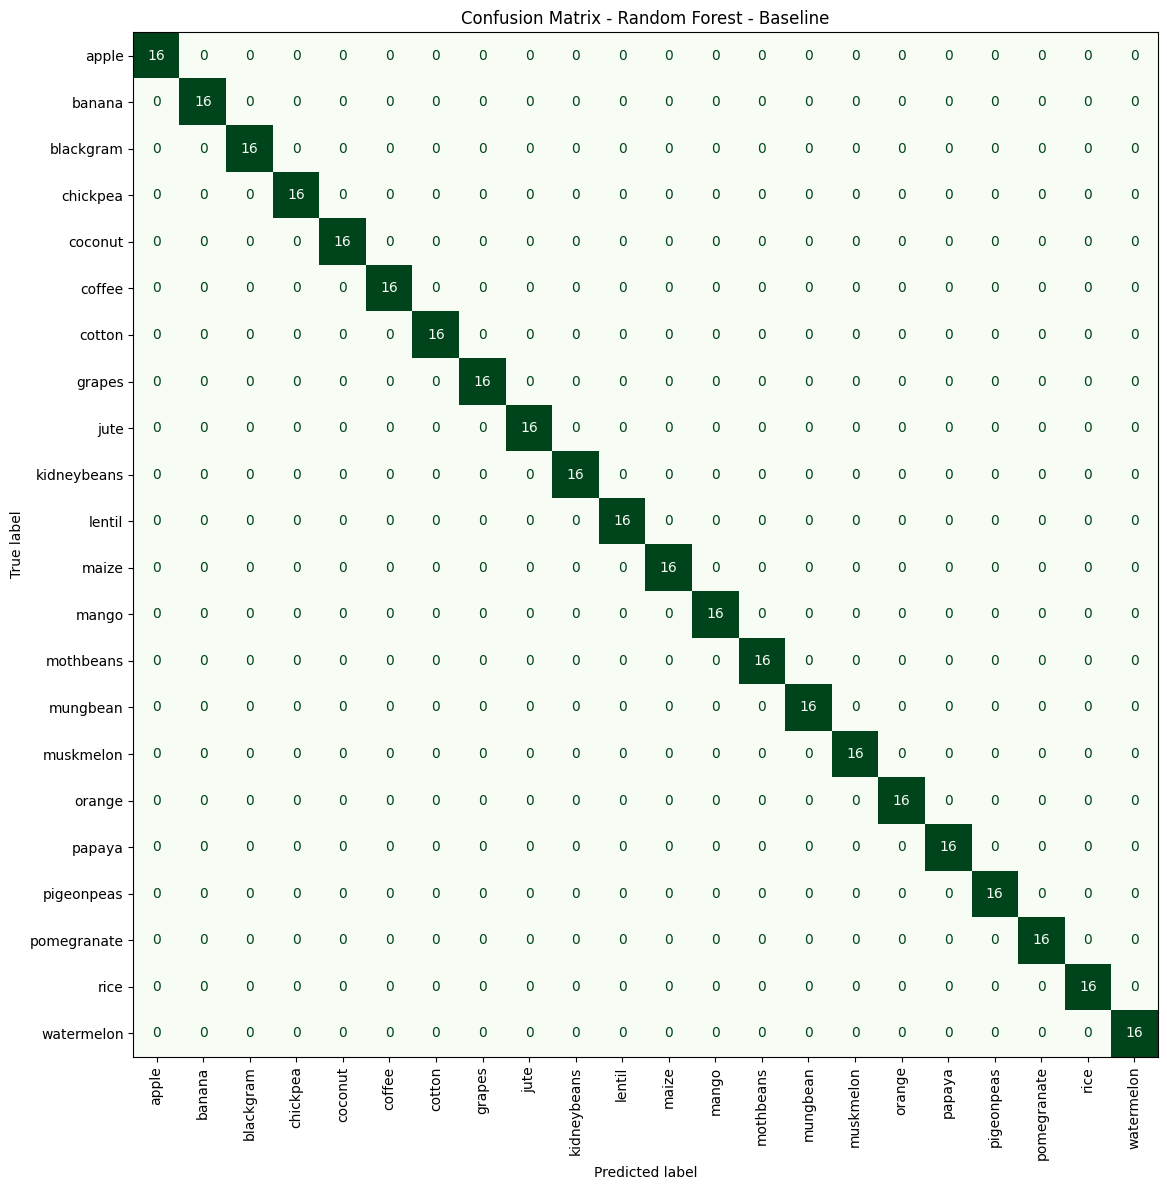

In [18]:
print(classification_report(y_test,best_pred,digits=4,zero_division=0))
fig,ax=plt.subplots(figsize=(14,12))
ConfusionMatrixDisplay.from_predictions(y_test,best_pred,xticks_rotation=90,cmap='Greens',colorbar=False,ax=ax)
ax.set_title(f'Confusion Matrix - {best_name}'); plt.tight_layout(); plt.show()

,importance
rainfall,0.2223
humidity,0.2150
K,0.1748
P,0.1548
N,0.1096
temperature,0.0730
ph,0.0504


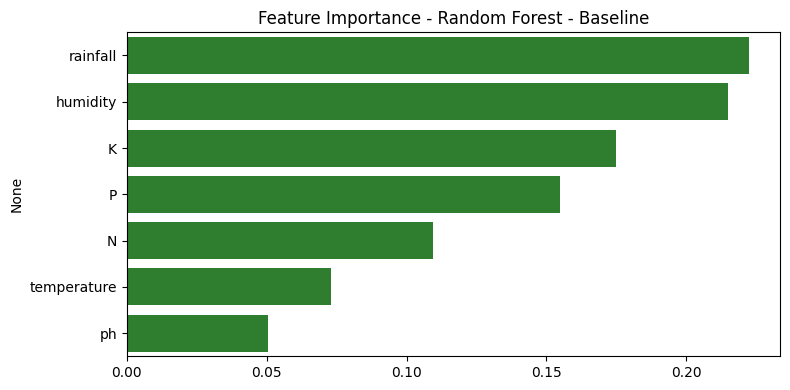

In [19]:
if 'Random Forest' in best_name:
    importance=pd.Series(best_model.feature_importances_,index=FEATURES).sort_values(ascending=False)
    display(importance.to_frame('importance').round(4))
    plt.figure(figsize=(8,4)); sns.barplot(x=importance.values,y=importance.index,color='forestgreen')
    plt.title(f'Feature Importance - {best_name}'); plt.tight_layout(); plt.show()
else:
    print('RBF SVM does not provide direct impurity-based feature importance.')

## 7. Model Comparison & Selection

In [20]:
leader=results.iloc[0]; runner=results.iloc[1]
print('Selected model:',best_name)
print(f"Accuracy: {leader['Accuracy']:.4f}")
print(f"Macro F1: {leader['Macro F1']:.4f}")
print(f"Macro F1 advantage over second place: {leader['Macro F1']-runner['Macro F1']:.4f}")
print('The selected model gives the best balance of precision and recall across all 22 crops on the held-out test set.')

Selected model: Random Forest - Baseline
Accuracy: 1.0000
Macro F1: 1.0000
Macro F1 advantage over second place: 0.0000
The selected model gives the best balance of precision and recall across all 22 crops on the held-out test set.


## 8. Three Sample Recommendations

In [21]:
sample_X=X_test.iloc[:3].copy()
sample_actual=y_test.iloc[:3].to_numpy()
sample_pred=best_model.predict(sample_X)
sample_output=sample_X.reset_index(drop=True)
sample_output['Actual Crop']=sample_actual
sample_output['Recommended Crop']=sample_pred
sample_output['Correct']=sample_output['Actual Crop']==sample_output['Recommended Crop']
display(sample_output)
for i,row in sample_output.iterrows():
    print(f"Sample {i+1}: N={row['N']:.2f}, P={row['P']:.2f}, K={row['K']:.2f}, "
          f"temperature={row['temperature']:.2f} C, humidity={row['humidity']:.2f}%, "
          f"pH={row['ph']:.2f}, rainfall={row['rainfall']:.2f} mm -> "
          f"recommended crop: {row['Recommended Crop']}; actual crop: {row['Actual Crop']}.")

,N,P,K,temperature,humidity,ph,rainfall,Actual Crop,Recommended Crop,Correct
0,75,41,35,24.970426,78.626977,6.856833,166.641525,jute,jute,True
1,21,74,15,29.490967,67.106044,6.471862,153.250451,pigeonpeas,pigeonpeas,True
2,100,41,22,22.420475,84.557947,7.318802,93.465956,cotton,cotton,True


Sample 1: N=75.00, P=41.00, K=35.00, temperature=24.97 C, humidity=78.63%, pH=6.86, rainfall=166.64 mm -> recommended crop: jute; actual crop: jute.
Sample 2: N=21.00, P=74.00, K=15.00, temperature=29.49 C, humidity=67.11%, pH=6.47, rainfall=153.25 mm -> recommended crop: pigeonpeas; actual crop: pigeonpeas.
Sample 3: N=100.00, P=41.00, K=22.00, temperature=22.42 C, humidity=84.56%, pH=7.32, rainfall=93.47 mm -> recommended crop: cotton; actual crop: cotton.


## 9. User Crop Recommendation Function

In [22]:
def recommend_crop(N,P,K,temperature,humidity,ph,rainfall):
    values=[N,P,K,temperature,humidity,ph,rainfall]
    if not all(np.isfinite(values)): raise ValueError('All inputs must be finite numbers.')
    if min(N,P,K,rainfall)<0: raise ValueError('N, P, K and rainfall cannot be negative.')
    if not 0<=humidity<=100: raise ValueError('Humidity must be between 0 and 100%.')
    if not 0<ph<=14: raise ValueError('pH must be greater than 0 and at most 14.')
    user=pd.DataFrame([values],columns=FEATURES)
    recommendation=best_model.predict(user)[0]
    print('Recommended crop:',recommendation)
    return recommendation
example=X_test.iloc[0]
recommend_crop(example.N,example.P,example.K,example.temperature,example.humidity,example.ph,example.rainfall)

Recommended crop: jute


'jute'

## 10. Conclusion, Limitations & Improvements

This notebook uses all 1,760 records, meeting the assignment's 1,000-2,000 sample requirement. It compares the required ensemble and SVM approaches, tunes four Random Forest hyperparameters, evaluates multiclass performance, and demonstrates recommendations.

**Limitations:** The model is limited to 22 known crops and seven variables. It does not include location, season, soil texture, sunlight, irrigation, pests, crop rotation, cost, or market demand. A strong test score on this dataset does not guarantee safe performance on real farms.

**Improvements:** Validate on Malaysian farm data across seasons, add location and soil variables, use repeated or nested cross-validation, test on an external dataset, monitor model drift, and refer uncertain cases to an agronomist.

**Responsible use:** The recommendation supports but does not replace laboratory soil testing and advice from qualified agricultural officers.

## 11. Save the Best Model (Optional)

In [23]:
import joblib
joblib.dump({'model':best_model,'features':FEATURES},'best_crop_recommendation_model_1760.joblib')
print('Saved: best_crop_recommendation_model_1760.joblib')

Saved: best_crop_recommendation_model_1760.joblib


##12. Interactive Web Application (Gradio Interface)
We have added an additional web app To make it easy for non-technical users to access our trained Random Forest model, we build a web application interface using Gradio inside google colab.

In [24]:
!pip install -q gradio

In [25]:
import gradio as gr
import pandas as pd
import joblib
import numpy as np

# Load the saved model and metadata safely
model_data = joblib.load('best_crop_recommendation_model_1760.joblib')
web_model = model_data['model']
web_features = model_data['features']

def predict_crop_web(n, p, k, temp, hum, ph, rain):
    # Basic input checks
    if min(n, p, k, rain) < 0:
        return "Error: Nutrient levels (N, P, K) and Rainfall cannot be negative!"
    if not (0 <= hum <= 100):
        return "Error: Relative Humidity must be between 0% and 100%!"
    if not (0 < ph <= 14):
        return "Error: pH must be a positive value up to 14!"

    # Prepare the input DataFrame for prediction
    input_df = pd.DataFrame([[n, p, k, temp, hum, ph, rain]], columns=web_features)

    # Make prediction
    prediction = web_model.predict(input_df)[0]
    return f"🌱 Recommended Crop: {prediction.upper()}"

# Define the Gradio web interface
app = gr.Interface(
    fn=predict_crop_web,
    inputs=[
        gr.Slider(0, 150, value=50, label="Nitrogen (N) - Soil Content"),
        gr.Slider(5, 150, value=50, label="Phosphorus (P) - Soil Content"),
        gr.Slider(5, 205, value=50, label="Potassium (K) - Soil Content"),
        gr.Number(value=25.0, label="Temperature (°C)"),
        gr.Slider(0, 100, value=60, label="Humidity (%)"),
        gr.Slider(1, 14, value=6.5, step=0.1, label="Soil pH"),
        gr.Number(value=100.0, label="Rainfall (mm)")
    ],
    outputs=gr.Textbox(label="Recommendation Result", placeholder="Your recommendation will appear here..."),
    title="🌾 Crop Recommendation Assistant",
    description="Enter your soil nutrients and climate measurements to receive a crop recommendation backed by the trained Random Forest model.",
    theme="soft"
)

# Launch the web interface (Generates a public shareable URL valid for 72 hours)
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4b070138dea2201604.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
